In [1]:
!pip install transformers datasets evaluate sentencepiece accelerate -q

In [2]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import Dataset

In [3]:
mecorpus = pd.read_csv(
"/kaggle/input/datasets/rutvikgokhale/marathi-hate-dataset/MeCorpus_Roman_Devanagari_10M.csv"
)

train_df = pd.read_excel(
"/kaggle/input/datasets/rutvikgokhale/marathi-hate-dataset/hate_bin_train.xlsx"
)

valid_df = pd.read_excel(
"/kaggle/input/datasets/rutvikgokhale/marathi-hate-dataset/hate_bin_valid.xlsx"
)

test_df = pd.read_excel(
"/kaggle/input/datasets/rutvikgokhale/marathi-hate-dataset/hate_bin_test.xlsx"
)

In [4]:
mahahate = pd.concat(
    [train_df, valid_df, test_df],
    ignore_index=True
)

In [5]:
print("MeCorpus:", mecorpus.shape)
print("MahaHate:", mahahate.shape)

MeCorpus: (9999882, 1)
MahaHate: (37500, 2)


In [6]:
corpus = mecorpus.sample(
    n=20000,
    random_state=42
)

corpus = corpus.dropna()

In [7]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "google/muril-base-cased"
)

config.json:   0%|          | 0.00/411 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/206 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/3.16M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/113 [00:00<?, ?B/s]

In [8]:
dataset = Dataset.from_pandas(
    corpus[['text']]
)

In [9]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)


Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

In [10]:
from transformers import AutoModelForMaskedLM

mlm_model = AutoModelForMaskedLM.from_pretrained(
    "google/muril-base-cased"
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  953MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  953MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] BertForMaskedLM LOAD REPORT from: google/muril-base-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.weight    | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [11]:
from transformers import DataCollatorForLanguageModeling

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=True,
    mlm_probability=0.15
)

In [12]:
from transformers import TrainingArguments

mlm_args = TrainingArguments(
    output_dir="./muril_domain",
    num_train_epochs=1,
    per_device_train_batch_size=16,
    save_strategy="epoch",
    logging_steps=100,
    report_to="none"
)

In [13]:
from transformers import Trainer

mlm_trainer = Trainer(
    model=mlm_model,
    args=mlm_args,
    train_dataset=tokenized_dataset,
    data_collator=data_collator
)

In [14]:
mlm_trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss
100,10.259944
200,9.682231
300,9.424567
400,9.020629
500,9.037672
600,8.892942


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=625, training_loss=9.357002368164062, metrics={'train_runtime': 667.923, 'train_samples_per_second': 29.944, 'train_steps_per_second': 0.936, 'total_flos': 893753763825600.0, 'train_loss': 9.357002368164062, 'epoch': 1.0})

In [15]:
mlm_model.save_pretrained(
    "/kaggle/working/domain_adapted_muril"
)

tokenizer.save_pretrained(
    "/kaggle/working/domain_adapted_muril"
)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/domain_adapted_muril/tokenizer_config.json',
 '/kaggle/working/domain_adapted_muril/tokenizer.json')

In [16]:
mahahate["label"] = mahahate["label"].map({
    "NOT":0,
    "HOF":1
})

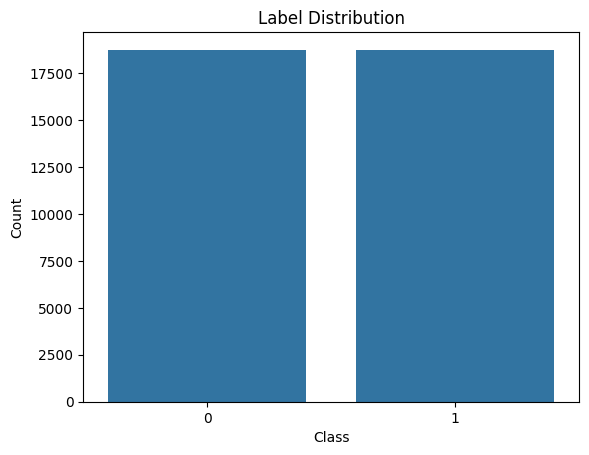

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x=mahahate["label"])
plt.title("Label Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [17]:
from sklearn.model_selection import train_test_split

train_texts,\
test_texts,\
train_labels,\
test_labels = train_test_split(
    mahahate["text"],
    mahahate["label"],
    test_size=0.20,
    stratify=mahahate["label"],
    random_state=42
)

In [18]:
tokenizer = AutoTokenizer.from_pretrained(
    "/kaggle/working/domain_adapted_muril"
)

In [19]:
train_encodings = tokenizer(
    list(train_texts),
    truncation=True,
    padding=True
)

test_encodings = tokenizer(
    list(test_texts),
    truncation=True,
    padding=True
)

In [20]:
class MarathiDataset(torch.utils.data.Dataset):

    def __init__(self, encodings, labels):
        self.encodings=encodings
        self.labels=list(labels)

    def __getitem__(self, idx):

        item={
            key:torch.tensor(val[idx])
            for key,val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            self.labels[idx]
        )

        return item

    def __len__(self):
        return len(self.labels)

In [21]:
train_dataset = MarathiDataset(
    train_encodings,
    train_labels
)

test_dataset = MarathiDataset(
    test_encodings,
    test_labels
)

In [22]:
import evaluate
import numpy as np

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )

    f1 = f1_metric.compute(
        predictions=predictions,
        references=labels,
        average="weighted"
    )

    return {
        "accuracy": accuracy["accuracy"],
        "f1": f1["f1"]
    }

In [23]:
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

muril_model = AutoModelForSequenceClassification.from_pretrained(
    "google/muril-base-cased",
    num_labels=2
)

muril_args = TrainingArguments(
    output_dir="./muril_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    report_to="none"
)

muril_trainer = Trainer(
    model=muril_model,
    args=muril_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: google/muril-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params w

In [24]:
muril_trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.948054,0.523985,0.898667,0.898657
2,0.455436,0.548579,0.910000,0.909994
3,0.312753,0.531882,0.909467,0.909464


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2814, training_loss=0.5185312435147436, metrics={'train_runtime': 3535.6874, 'train_samples_per_second': 25.455, 'train_steps_per_second': 0.796, 'total_flos': 1.5031246815e+16, 'train_loss': 0.5185312435147436, 'epoch': 3.0})

In [25]:
muril_results = muril_trainer.evaluate()

muril_predictions = muril_trainer.predict(
    test_dataset
)

muril_y_pred = muril_predictions.predictions.argmax(axis=1)

print(muril_results)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.312753,0.531882,3,0.909467,0.909464


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.531882107257843, 'eval_accuracy': 0.9094666666666666, 'eval_f1': 0.9094642185791372}


In [26]:
muril_history = pd.DataFrame(muril_trainer.state.log_history)
muril_history.to_csv("muril_history.csv", index=False)
muril_loss = muril_history.dropna(subset=["loss"])
print(muril_loss.head())

In [27]:
from sklearn.metrics import classification_report

print(
    classification_report(
        test_labels,
        muril_y_pred
    )
)

              precision    recall  f1-score   support

           0       0.91      0.91      0.91      3750
           1       0.91      0.90      0.91      3750

    accuracy                           0.91      7500
   macro avg       0.91      0.91      0.91      7500
weighted avg       0.91      0.91      0.91      7500



In [28]:
dapt_model = AutoModelForSequenceClassification.from_pretrained(
    "/kaggle/working/domain_adapted_muril",
    num_labels=2
)

dapt_args = TrainingArguments(
    output_dir="./dapt_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    report_to="none"
)

dapt_trainer = Trainer(
    model=dapt_model,
    args=dapt_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: /kaggle/working/domain_adapted_muril
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [29]:
dapt_trainer.train()

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,0.933734,0.517245,0.903600,0.903560
2,0.460174,0.497233,0.913200,0.913195
3,0.308356,0.489370,0.915333,0.915333


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2814, training_loss=0.5169950944782574, metrics={'train_runtime': 3548.1536, 'train_samples_per_second': 25.365, 'train_steps_per_second': 0.793, 'total_flos': 1.5031246815e+16, 'train_loss': 0.5169950944782574, 'epoch': 3.0})

In [30]:
dapt_results = dapt_trainer.evaluate()

dapt_predictions = dapt_trainer.predict(
    test_dataset
)

dapt_y_pred = dapt_predictions.predictions.argmax(axis=1)

print(dapt_results)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1
0.308356,0.489370,3,0.915333,0.915333


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.489369660615921, 'eval_accuracy': 0.9153333333333333, 'eval_f1': 0.9153333318281481}


In [31]:
dapt_history = pd.DataFrame(dapt_trainer.state.log_history)
dapt_history.to_csv("dapt_history.csv", index=False)
dapt_loss = dapt_history.dropna(subset=["loss"])
print(dapt_loss.head())

In [32]:
print(
    classification_report(
        test_labels,
        dapt_y_pred
    )
)

              precision    recall  f1-score   support

           0       0.92      0.92      0.92      3750
           1       0.92      0.92      0.92      3750

    accuracy                           0.92      7500
   macro avg       0.92      0.92      0.92      7500
weighted avg       0.92      0.92      0.92      7500



In [33]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Model": ["MuRIL", "DAPT-MuRIL"],
    "Accuracy": [
        muril_results["eval_accuracy"],
        dapt_results["eval_accuracy"]
    ],
    "F1 Score": [
        muril_results["eval_f1"],
        dapt_results["eval_f1"]
    ]
})

display(comparison_df)


,Model,Accuracy,F1 Score
0,MuRIL,0.909467,0.909464
1,DAPT-MuRIL,0.915333,0.915333


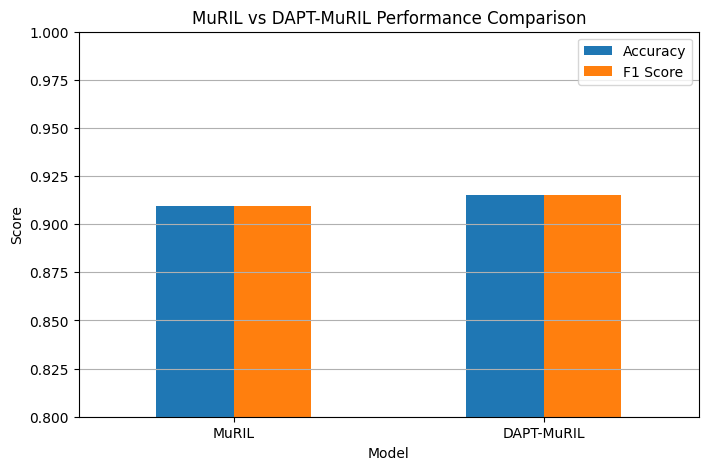

In [34]:
import matplotlib.pyplot as plt

comparison_df.plot(
    x="Model",
    y=["Accuracy", "F1 Score"],
    kind="bar",
    figsize=(8,5),
    rot=0
)

plt.title("MuRIL vs DAPT-MuRIL Performance Comparison")
plt.ylabel("Score")
plt.ylim(0.80,1.0)

plt.grid(axis="y")

plt.show()

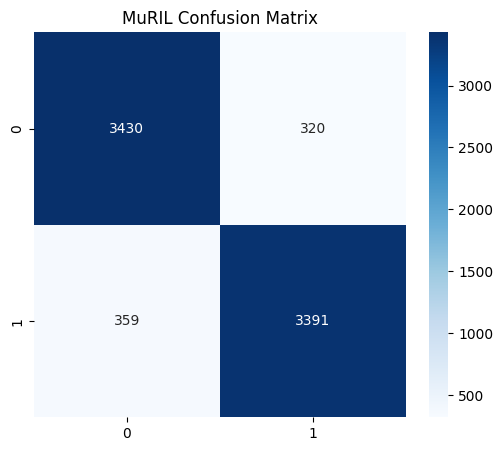

In [35]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm_muril = confusion_matrix(
    test_labels,
    muril_y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_muril,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("MuRIL Confusion Matrix")

plt.show()

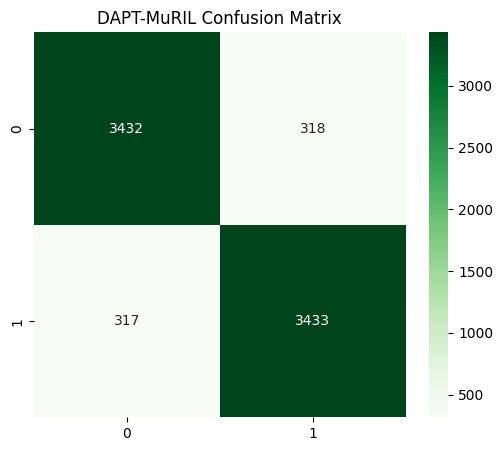

In [36]:
cm_dapt = confusion_matrix(
    test_labels,
    dapt_y_pred
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_dapt,
    annot=True,
    fmt='d',
    cmap='Greens'
)

plt.title("DAPT-MuRIL Confusion Matrix")

plt.show()

In [37]:
print("muril_trainer" in globals())
print("dapt_trainer" in globals())

True
True


In [39]:
muril_history = pd.read_csv("muril_history.csv")
dapt_history  = pd.read_csv("dapt_history.csv")

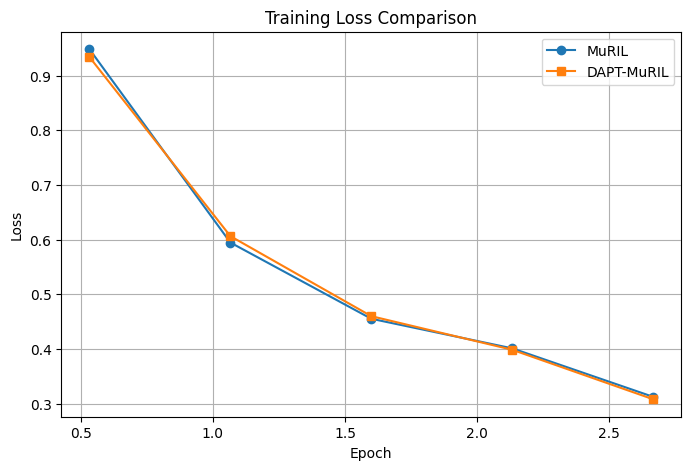

In [40]:
muril_history = pd.DataFrame(muril_trainer.state.log_history)
dapt_history  = pd.DataFrame(dapt_trainer.state.log_history)

muril_loss = muril_history.dropna(subset=["loss"])
dapt_loss  = dapt_history.dropna(subset=["loss"])

plt.figure(figsize=(8,5))
plt.plot(muril_loss["epoch"], muril_loss["loss"], marker="o", label="MuRIL")
plt.plot(dapt_loss["epoch"], dapt_loss["loss"], marker="s", label="DAPT-MuRIL")
plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

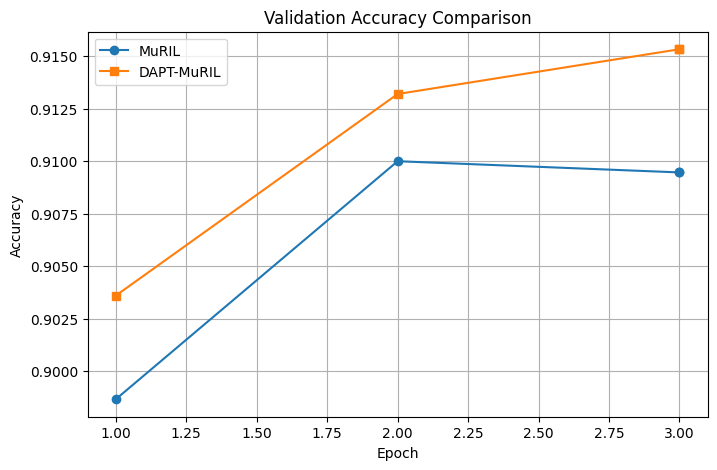

In [41]:
muril_acc = muril_history.dropna(
    subset=["eval_accuracy"]
)

dapt_acc = dapt_history.dropna(
    subset=["eval_accuracy"]
)

plt.figure(figsize=(8,5))

plt.plot(
    muril_acc["epoch"],
    muril_acc["eval_accuracy"],
    marker="o",
    label="MuRIL"
)

plt.plot(
    dapt_acc["epoch"],
    dapt_acc["eval_accuracy"],
    marker="s",
    label="DAPT-MuRIL"
)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

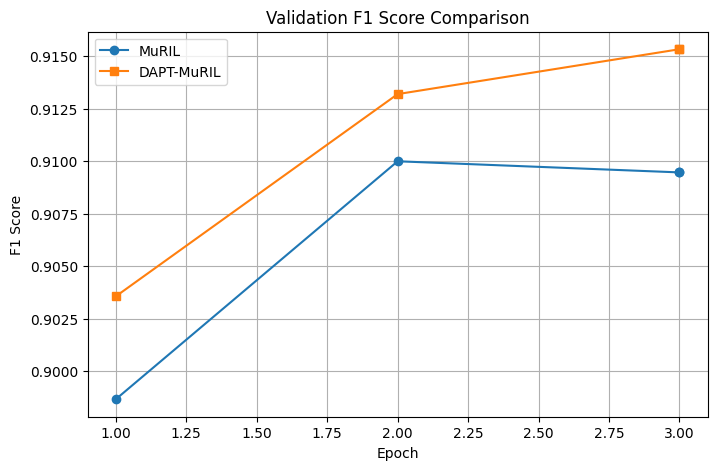

In [42]:
muril_history = pd.DataFrame(
    muril_trainer.state.log_history
)

dapt_history = pd.DataFrame(
    dapt_trainer.state.log_history
)

muril_f1 = muril_history.dropna(
    subset=["eval_f1"]
)

dapt_f1 = dapt_history.dropna(
    subset=["eval_f1"]
)

plt.figure(figsize=(8,5))

plt.plot(
    muril_f1["epoch"],
    muril_f1["eval_f1"],
    marker="o",
    label="MuRIL"
)

plt.plot(
    dapt_f1["epoch"],
    dapt_f1["eval_f1"],
    marker="s",
    label="DAPT-MuRIL"
)

plt.title("Validation F1 Score Comparison")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")

plt.legend()
plt.grid(True)

plt.show()

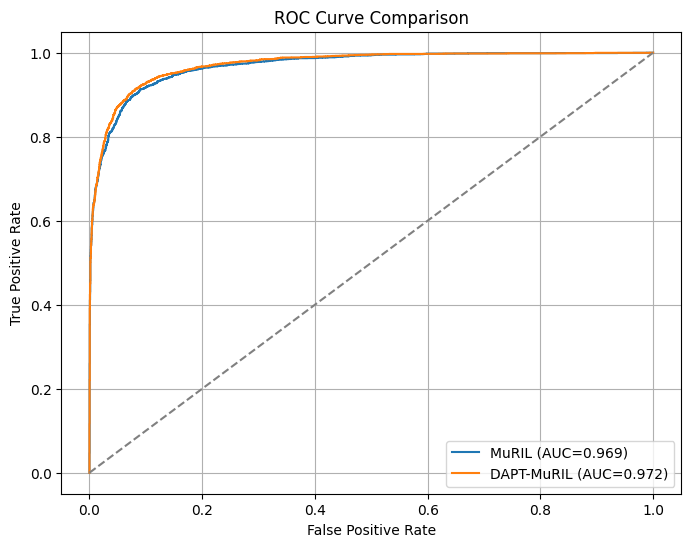

MuRIL AUC: 0.9691
DAPT-MuRIL AUC: 0.9723


In [46]:
from sklearn.metrics import roc_curve, auc
from scipy.special import softmax
import matplotlib.pyplot as plt

muril_probs = softmax(muril_predictions.predictions, axis=1)[:, 1]
dapt_probs  = softmax(dapt_predictions.predictions, axis=1)[:, 1]

muril_fpr, muril_tpr, _ = roc_curve(test_labels, muril_probs)
muril_auc = auc(muril_fpr, muril_tpr)

dapt_fpr, dapt_tpr, _ = roc_curve(test_labels, dapt_probs)
dapt_auc = auc(dapt_fpr, dapt_tpr)

plt.figure(figsize=(8,6))
plt.plot(muril_fpr, muril_tpr, label=f"MuRIL (AUC={muril_auc:.3f})")
plt.plot(dapt_fpr, dapt_tpr, label=f"DAPT-MuRIL (AUC={dapt_auc:.3f})")
plt.plot([0,1], [0,1], '--', color="gray")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.show()

print("MuRIL AUC:", round(muril_auc, 4))
print("DAPT-MuRIL AUC:", round(dapt_auc, 4))

In [45]:
import pandas as pd
import torch

samples = [
    "तू खूप चांगला मित्र आहेस",
    "हा व्हिडिओ खूप छान आहे",
    "तुझ्यासारख्यांना बाहेर काढलं पाहिजे",
    "तू मूर्ख आहेस"
]

results = []

for text in samples:

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True
    )

    # MuRIL Prediction
    muril_inputs = {
        k: v.to(muril_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        muril_output = muril_model(**muril_inputs)

    muril_pred = muril_output.logits.argmax(dim=1).item()

    # DAPT-MuRIL Prediction
    dapt_inputs = {
        k: v.to(dapt_model.device)
        for k, v in inputs.items()
    }

    with torch.no_grad():
        dapt_output = dapt_model(**dapt_inputs)

    dapt_pred = dapt_output.logits.argmax(dim=1).item()

    results.append([
        text,
        "HOF" if muril_pred == 1 else "NOT",
        "HOF" if dapt_pred == 1 else "NOT"
    ])

comparison_predictions = pd.DataFrame(
    results,
    columns=[
        "Text",
        "MuRIL Prediction",
        "DAPT-MuRIL Prediction"
    ]
)

display(comparison_predictions)

,Text,MuRIL Prediction,DAPT-MuRIL Prediction
0,तू खूप चांगला मित्र आहेस,NOT,NOT
1,हा व्हिडिओ खूप छान आहे,NOT,NOT
2,तुझ्यासारख्यांना बाहेर काढलं पाहिजे,HOF,HOF
3,तू मूर्ख आहेस,HOF,HOF
